# Demand-Driven Staffing Optimization - Store 85 Case Study

Forecast daily demand, convert it into a staffing recommenedation, and quantify the trade-off between labor cost and understaffing risk vs. a fixed schedule.

## 1. Load and merge the data
Load the sales data and store metadata, and combine them into one table

In [99]:
import pandas as pd

# Load the daily sales data, telling pandas the Date column contain real dates
df = pd.read_csv('../data/raw/train.csv', parse_dates=['Date'])
df.head()

/var/folders/zm/kyh0_bdx6sv9kwy3qnrmy72c0000gn/T/ipykernel_8773/1708831857.py:4: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/raw/train.csv', parse_dates=['Date'])


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [100]:
# Load store background info (store type, competition distance, etc.)
store = pd.read_csv('../data/raw/store.csv')
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [101]:
# Combine both tables by matching on Store ID
df = df.merge(store, on='Store', how='left')
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## 2. Explore the data
Check the size of the dataset and how many stores/days it covers.

In [102]:
df.shape # (rows, columns)

(1017209, 18)

In [103]:
df['Store'].nunique() # how many different stores

1115

In [104]:
df['Date'].min(), df['Date'].max() # date range covered

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

## 3. Focus on one store
Filter to a single store, open days only, to build and validate the pipeline before scaling up.

In [105]:
# Filter to Store 85, only days it was actually open
store_85 = df[df['Store'] == 85]
store_85 = store_85[store_85['Open'] == 1]
store_85.shape

(942, 18)

## 4. Visualize the demand pattern

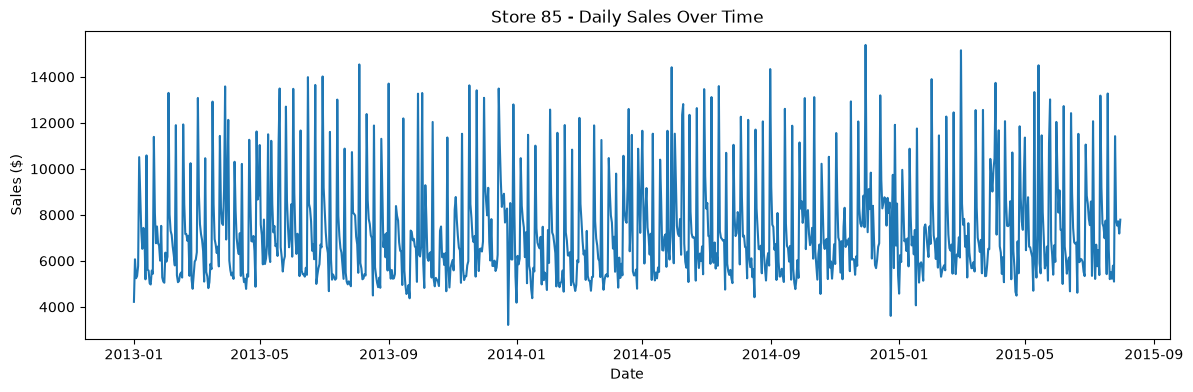

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,4))
plt.plot(store_85['Date'], store_85['Sales'])
plt.title('Store 85 - Daily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Sales ($)')
plt.show()

## 5. Quantify the pattern by day of week

Note: Rossman's DayOfWeek runs 1-7 (Monday=1, Sunday=7), not Python's usual 0-6.

In [107]:
store_85['DayOfWeek'].value_counts()

DayOfWeek
5    135
4    135
3    135
2    135
1    134
7    134
6    134
Name: count, dtype: int64

In [108]:
store_85.groupby('DayOfWeek')['Sales'].mean()

DayOfWeek
1     7644.253731
2     6549.348148
3     6476.451852
4     6582.570370
5     6795.911111
6     5543.156716
7    11335.529851
Name: Sales, dtype: float64

Finding: Sunday (day 7) sales average $11,336 - 73% higher than the weekday average - a pattern a fixed schedule can't react to.

## 6. Train/test split
Hold out the most recent 3 months as a test set, to check the forecast against days the model never saw.

In [109]:
train = store_85[store_85['Date'] < '2015-05-01']
test = store_85[store_85['Date'] >= '2015-05-01']

print('Train rows:', len(train))
print('Test rows:', len(test))

Train rows: 850
Test rows: 92


## 7. Baseline forecast: day-of-week average
A simple, explainable starting point - predict each day as the historical average for day of week, using ONLY training data (never peek at the future).

In [110]:
# Average sales per day-of-week, calculated only on training data
dow_averages = train.groupby('DayOfWeek')['Sales'].mean()
dow_averages

DayOfWeek
1     7588.338843
2     6528.983607
3     6443.057377
4     6538.934426
5     6764.611570
6     5571.752066
7    11284.578512
Name: Sales, dtype: float64

In [111]:
# Apply the lookup to the test set
baseline_prediction = test['DayOfWeek'].map(dow_averages)

comparison = pd.DataFrame({
    'Date': test['Date'],
    'Actual_Sales': test['Sales'],
    'Predicted_Sales': baseline_prediction
})
comparison.head(10)

,Date,Actual_Sales,Predicted_Sales
84,2015-07-31,7791,6764.611570
1199,2015-07-30,7187,6538.934426
2314,2015-07-29,7719,6443.057377
3429,2015-07-28,7533,6528.983607
4544,2015-07-27,7788,7588.338843
5659,2015-07-26,11421,11284.578512
6774,2015-07-25,5099,5571.752066
7889,2015-07-24,5791,6764.611570
9004,2015-07-23,5223,6538.934426
10119,2015-07-22,5504,6443.057377


In [112]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(comparison['Actual_Sales'], comparison['Predicted_Sales'])
print(f'Baseline MAPE: {mape * 100:.1f}%')

Baseline MAPE: 13.0%


## 8. Improved forecast: gradient boosting
Add promotions and holiday flags on top of day-of-week to see if can beat the baseline.

In [113]:
# StateHoliday is text ('0' = no holiday, letters = holiday types) - convert to a simple flag
store_85 = store_85.copy()
store_85['IsHoliday'] = (store_85['StateHoliday'] != '0').astype(int)
store_85[['StateHoliday', 'IsHoliday']].head(10)

,StateHoliday,IsHoliday
84,0,0
1199,0,0
2314,0,0
3429,0,0
4544,0,0
5659,0,0
6774,0,0
7889,0,0
9004,0,0
10119,0,0


In [114]:
# Re-split now that we/ve added the IsHoliday column
train = store_85[store_85['Date'] < '2015-05-01']
test = store_85[store_85['Date'] >= '2015-05-01']

print('Train rows:', len(train))
print('Test rows:', len(test))

Train rows: 850
Test rows: 92


In [115]:
from sklearn.ensemble import GradientBoostingRegressor

# Features = the input columns the model will learn from
features = ['DayOfWeek', 'Promo', 'IsHoliday', 'SchoolHoliday']

X_train = train[features]
y_train = train['Sales']

X_test = test[features]
y_test = test['Sales']

model = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

print('Model trained!')

Model trained!


In [116]:
predictions = model.predict(X_test)

mape_model = mean_absolute_percentage_error(y_test, predictions)
print(f'Baseline MAPE (day-of-week average): 13.0%')
print(f'Gradient boosting MAPE: {mape_model * 100:.1f}%')

Baseline MAPE (day-of-week average): 13.0%
Gradient boosting MAPE: 9.8%


## 9. What drove the model's predictions?

In [117]:
importances = pd.Series(model.feature_importances_, index=features)
importances.sort_values(ascending=False)

DayOfWeek        0.787380
Promo            0.183834
IsHoliday        0.021612
SchoolHoliday    0.007174
dtype: float64

Result: DayOfWeek 78.7%, Promo 18.4%, IsHoliday 2.2%, SchoolHoliday 0.7% - day-of-week dominates, but promotions meaningfully sharpen the forecast.

## 10. Convert forecast to staffing recommendation
Staffing rule (documented assumption - real staffing data isn't public): 2 minimum staff + 1 additional staff per $1,500 in predicted daily sales.

In [118]:
import numpy as np

def recommend_staff(predicted_sales):
    min_staff = 2
    sales_per_staff = 1500
    extra_staff = np.ceil(predicted_sales / sales_per_staff)
    return min_staff + extra_staff

# Test it on our model's predictions
recommended_staff = recommend_staff(predictions)
recommended_staff[:10]

array([ 7.,  7.,  7.,  7.,  8., 10.,  6.,  6.,  6.,  6.])

## 11. Fixed baseline for comparison
What a flat, one-size-fits-all schedule would look like, based on average demand. 

In [119]:
avg_train_sales = train['Sales'].mean()
fixed_staff_level = int(np.ceil(2 + np.ceil(avg_train_sales / 1500)))

print(f'Average training sales: ${avg_train_sales:.0f}')
print(f'Fixed staffing level (same every day): {fixed_staff_level} staff')

Average training sales: $7243
Fixed staffing level (same every day): 7 staff


## 12. Cost comparison: demand-driven vs. fixed

In [120]:
hourly_wage = 15
shift_hours = 8

# Fixed schedule: same staff count every day, for all 92 test days
fixed_total_cost = fixed_staff_level * shift_hours * hourly_wage * len(test)

# Demand-driven: adds up the actual daily cost, which varies day to day
daily_costs_optimized = recommended_staff * shift_hours * hourly_wage
optimized_total_cost = daily_costs_optimized.sum()

print(f'Fixed schedule total cost (92 days): ${fixed_total_cost:,.0f}')
print(f'Demand-driven total cost (92 days): ${optimized_total_cost:,.0f}')
print(f'Difference: ${optimized_total_cost - fixed_total_cost:,.0f}')

Fixed schedule total cost (92 days): $77,280
Demand-driven total cost (92 days): $78,120
Difference: $840


## 13. The real trade-off: understaffing risk

In [121]:
understaffed_days = (fixed_staff_level < recommended_staff).sum()
total_days = len(test)

print(f'Days the fixed schedule (7 staff) would be understaffed: {understaffed_days} out of {total_days}')
print(f"That's {understaffed_days / total_days * 100:.1f}% of all test days")

Days the fixed schedule (7 staff) would be understaffed: 21 out of 92
That's 22.8% of all test days


Result: demand-driven staffing costs $840 more (1.1%) over 92 days, but the fixed schedule would understaff the store on 21 of 92 days (22.8%) - every high-demand day.

## 14. Visualize demand vs. staffing recommendation

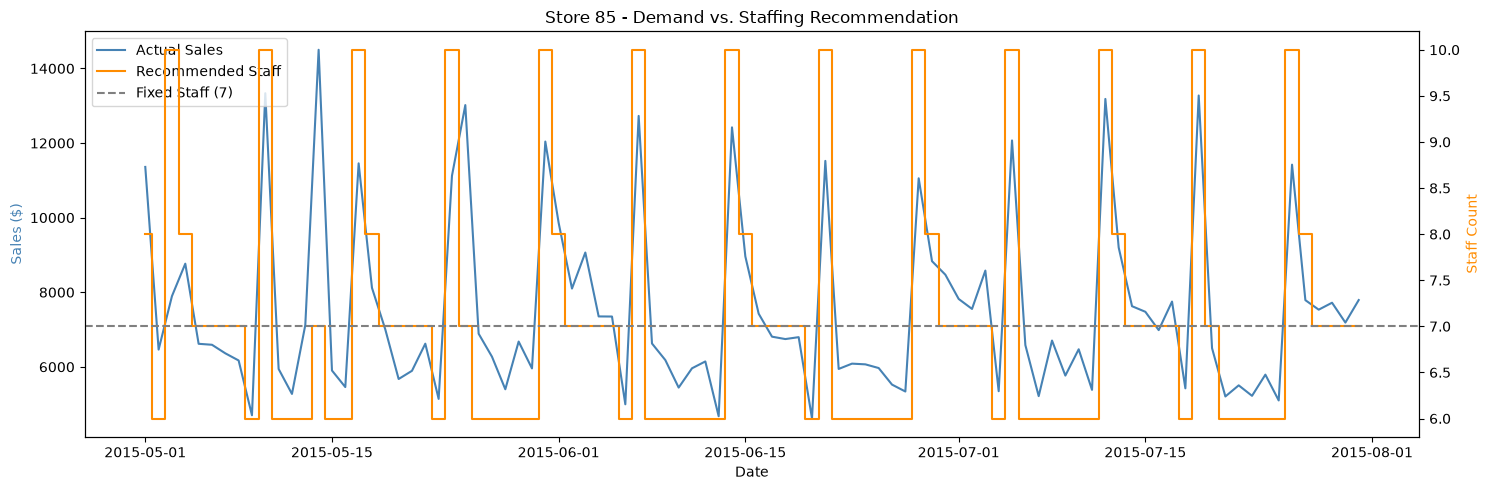

Plot saved!


In [122]:
fig, ax1 = plt.subplots(figsize=(15,5))

ax1.plot(test['Date'], test['Sales'], color='steelblue', label='Actual Sales')
ax1.set_ylabel('Sales ($)', color='steelblue')
ax1.set_xlabel('Date')

ax2 = ax1.twinx()
ax2.step(test['Date'], recommended_staff, color='darkorange', where='mid', label='Recommended Staff')
ax2.axhline(fixed_staff_level, color='gray', linestyle='--', label=f'Fixed Staff ({fixed_staff_level})')
ax2.set_ylabel('Staff Count', color='darkorange')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Store 85 - Demand vs. Staffing Recommendation')
plt.tight_layout()
plt.savefig('../dashboard/demand_vs_staffing.png', dpi=150)
plt.show()
print('Plot saved!')